In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('../data/processed_loan_data.csv')

# X = everything the model learns FROM
# y = what the model is trying to PREDICT
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:", X.columns.tolist())

Features shape: (614, 11)
Target shape: (614,)

Feature columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Income_to_Loan_Ratio', 'Total_Income_Log', 'LoanAmount_Log']


In [3]:
# Step 1: Split off 80% train, 20% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y        # keeps class balance in each split
)

# Step 2: Split the 20% temp into 10% validation, 10% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:  ", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:      ", X_test.shape)

# Verify class balance is preserved in each split
print("\nClass balance:")
print(f"  Train:      {y_train.mean():.2%} approved")
print(f"  Validation: {y_val.mean():.2%} approved")
print(f"  Test:       {y_test.mean():.2%} approved")

Training set:   (491, 11)
Validation set: (61, 11)
Test set:       (62, 11)

Class balance:
  Train:      68.64% approved
  Validation: 68.85% approved
  Test:       69.35% approved


In [4]:
# scale_pos_weight handles class imbalance
# formula: number of negatives / number of positives
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale = neg / pos
print(f"scale_pos_weight: {scale:.2f}")

model = XGBClassifier(
    n_estimators=200,        # number of trees
    max_depth=4,             # how deep each tree grows
    learning_rate=0.05,      # how fast the model learns
    scale_pos_weight=scale,  # handles class imbalance
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42
)

# Train on training set, validate on validation set
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print("✅ Model trained successfully")

scale_pos_weight: 0.46
✅ Model trained successfully


In [5]:
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]

print("=" * 40)
print("VALIDATION SET RESULTS")
print("=" * 40)
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred):.4f}")
print(f"F1 Score:  {f1_score(y_val, y_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

VALIDATION SET RESULTS
Accuracy:  0.7541
Precision: 0.8857
Recall:    0.7381
F1 Score:  0.8052
ROC-AUC:   0.8409

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.79      0.67        19
           1       0.89      0.74      0.81        42

    accuracy                           0.75        61
   macro avg       0.73      0.76      0.74        61
weighted avg       0.79      0.75      0.76        61



In [6]:
y_test_pred = model.predict(X_test)
y_test_proba = model.predict_proba(X_test)[:, 1]

print("=" * 40)
print("TEST SET RESULTS (FINAL)")
print("=" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_test_proba):.4f}")

TEST SET RESULTS (FINAL)
Accuracy:  0.7903
Precision: 0.8571
Recall:    0.8372
F1 Score:  0.8471
ROC-AUC:   0.8237


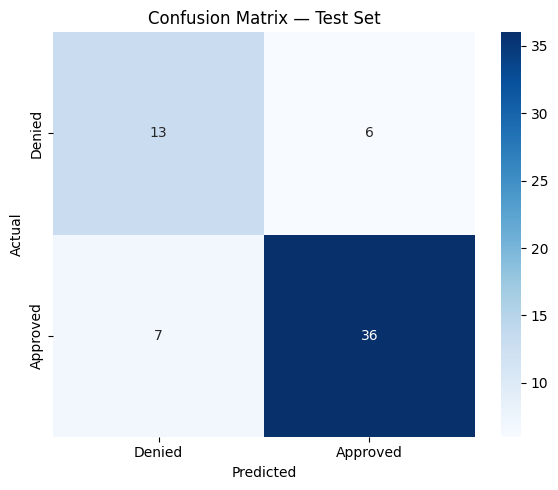

In [7]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Denied', 'Approved'],
            yticklabels=['Denied', 'Approved'])
plt.title('Confusion Matrix — Test Set')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

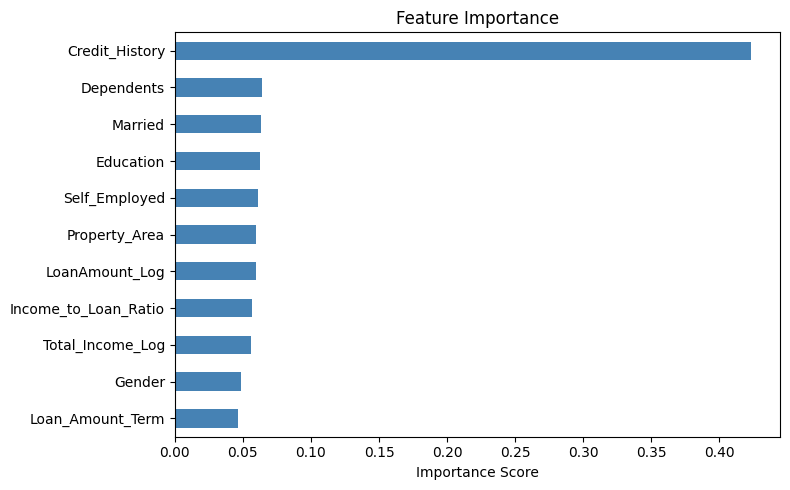

In [8]:
feat_imp = pd.Series(model.feature_importances_, index=X.columns)
feat_imp.sort_values().plot(kind='barh', figsize=(8, 5), color='steelblue')
plt.title('Feature Importance')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

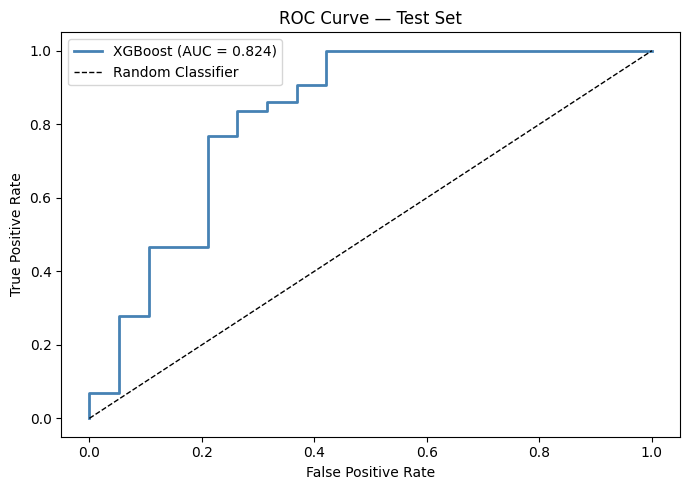

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
auc_score = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2,
         label=f'XGBoost (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Test Set')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import joblib
import os

os.makedirs('../src', exist_ok=True)
joblib.dump(model, '../src/loan_model.pkl')
print("✅ Model saved to src/loan_model.pkl")

✅ Model saved to src/loan_model.pkl


# Phase 3 — Model Training (XGBoost)

## Split Strategy
- 80% Training (491 rows)
- 10% Validation (61 rows)
- 10% Test (62 rows)
- Stratified split to preserve 68/32 class balance

## Model: XGBoost Classifier
- n_estimators: 200, max_depth: 4, learning_rate: 0.05
- scale_pos_weight applied to handle class imbalance

## Final Test Set Performance
- Accuracy:  79.03%
- Precision: 85.71%
- Recall:    83.72%
- F1 Score:  84.71%
- ROC-AUC:   82.37%

## Key Finding
- Credit_History is the dominant feature (0.43 importance)
- Gender has non-zero importance → warrants bias investigation in Phase 4
- Test scores exceed validation scores → no overfitting detected

## Output
- Model saved to: src/loan_model.pkl